# Bonus Task: Out-of-Distribution Evaluation on TotalSegmentator
Pretrained Swin UNETR Base / Small / Tiny (BTCV weights, **no fine-tuning**) on the 109 scans of the
TotalSegmentator dataset (`v300`, 1,939 scans) **test split**, scored on the 13 BTCV organs. Same metrics as Task 3 (official Dice, HD95, HD).

**Pipeline**
1. `src/ood_prepare.py`: ground truth = the 13 TotalSegmentator masks that correspond to BTCV organs, merged into one
   BTCV-indexed label map per scan (`ts_btcv/`; where two masks overlap, the higher BTCV index wins, affecting < 1 %
   of an organ's voxels in the median affected case). Also writes `survey.csv` and the case lists.
2. `src/ood_infer.py` (GPU, Colab): official BTCV test preprocessing (1.5 × 1.5 × 2.0 mm, HU window
   [−175, 250] → [0, 1], sliding window 96³, overlap 0.5, Gaussian blending) plus `Orientationd(RAS)`, fp32.
   Predictions are saved in the model grid (`pred_raw/`). Which GPU ran which case: `provenance/case_gpu.csv`.
3. `src/ood_eval.py` (local CPU): resample back to the label grid with the official `resample_3d`, then
   Dice / HD95 / HD with the Task 2/3 functions.
4. This notebook: tables and figures.

**Subsets used below**
- *all*: all 109 test scans (many do not contain the abdomen: head, neck, chest-only, leg scans)
- *abdominal*: 67 scans containing liver, spleen, both kidneys, pancreas and stomach
- *complete13*: 53 scans containing all 13 organs, used for the BTCV-comparable official Dice (absent organs
  would count as 0)

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (BTCV_ORGANS, FIGURES_DIR, METRICS_DIR, MODEL_CONFIGS, OOD_CASE_LIST_DIR, OOD_DATASET_DIR,
                        OOD_SURVEY_PATH)
from src.ood_eval import compute_extras

pd.set_option("display.precision", 3)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["tiny", "small", "base"]
MODEL_NAMES = {m: MODEL_CONFIGS[m]["name"] for m in MODELS}
MODEL_COLORS = {"tiny": "#eb6834", "small": "#1baf7a", "base": "#2a78d6"}  # same colours as Task 3
ORGANS = list(BTCV_ORGANS.values())
OVERLAP = 0.5
VOXEL_ML = 1.5 ** 3 / 1000  # all TotalSegmentator test labels are 1.5 mm isotropic (checked below)

plt.style.use("default")

In [2]:
# Load OOD metrics (one row per model x case x organ), BTCV metrics from Task 3 and scan metadata
ood = pd.concat(
    [pd.read_csv(METRICS_DIR / f"ood_totalseg_{m}_overlap{OVERLAP}.csv").assign(model=m) for m in MODELS],
    ignore_index=True,
)
ood["organ_in_gt"] = ood.gt_voxels > 0
ood["missed"] = ood.organ_in_gt & (ood.pred_voxels == 0)            # organ there, model predicts nothing
ood["phantom"] = ~ood.organ_in_gt & (ood.pred_voxels > 0)           # organ not in scan, model predicts it
ood["phantom_ml"] = np.where(ood.phantom, ood.pred_voxels * VOXEL_ML, 0.0)

btcv = pd.concat(
    [pd.read_csv(METRICS_DIR / f"btcv_metrics_{m}_overlap{OVERLAP}.csv") for m in MODELS], ignore_index=True
)

meta = pd.read_csv(OOD_DATASET_DIR / "meta.csv", sep=";").rename(columns={"image_id": "case"})
survey = pd.read_csv(OOD_SURVEY_PATH)
n_present = ood[ood.model == "base"].groupby("case").organ_in_gt.sum().rename("n_organs")
abdominal = set((OOD_CASE_LIST_DIR / "abdominal.txt").read_text().split())
scans = meta.merge(n_present, on="case").assign(abdominal=lambda d: d.case.isin(abdominal))
complete13 = set(scans.case[scans.n_organs == 13])

geo, cc = compute_extras(MODELS)  # truncation flags + largest-component HD95 (cached CSVs, slow the first time)
ood = ood.merge(geo[["case", "organ", "truncated", "scan_z_mm"]], on=["case", "organ"])

# Sanity checks
assert ood.groupby("model").case.nunique().eq(109).all(), "expected 109 test scans per model"
assert len(ood) == 109 * 13 * 3 and ood.dice.notna().all()
assert survey.zooms.eq("(1.5, 1.5, 1.5)").all() and survey.axcodes.eq("RAS").all()
print(f"scans: {len(scans)}  abdominal: {scans.abdominal.sum()}  complete13: {len(complete13)}  "
      f"no BTCV organ at all: {(scans.n_organs == 0).sum()}")

scans: 109  abdominal: 67  complete13: 53  no BTCV organ at all: 12


## Overall performance: BTCV vs. TotalSegmentator
- **Dice official**: as in the paper and Task 3, mean over the 13 organs per scan (absent → 0), then over scans.
  On TotalSegmentator only meaningful for *complete13* scans.
- **Dice present organs**: mean over all (scan, organ) pairs where the organ exists in the ground truth.
- HD95 median over (scan, organ) pairs where both masks exist.

In [3]:
def overall_row(d, official_cases=None):
    present = d[d.organ_in_gt]
    row = {"Dice present organs [%]": present.dice.mean() * 100,
           "HD95 median [mm]": present.hd95.median(),
           "Missed organs": int(d.missed.sum()),
           "Organ instances": int(d.organ_in_gt.sum())}
    if official_cases is not None:
        off = d[d.case.isin(official_cases)].groupby("case").dice.mean()
        row = {"Dice official [%]": off.mean() * 100, "Dice std over scans [%]": off.std() * 100, **row}
    return row

btcv["missed"] = btcv.organ_in_gt & btcv.hd95.isna()
rows = {}
for m in MODELS:
    b = btcv[btcv.model == m]
    rows[(MODEL_NAMES[m], "BTCV val (6)")] = overall_row(b, set(b.case))
    rows[(MODEL_NAMES[m], "TS complete13 (53)")] = overall_row(ood[(ood.model == m) & ood.case.isin(complete13)], complete13)
    rows[(MODEL_NAMES[m], "TS abdominal (67)")] = overall_row(ood[(ood.model == m) & ood.case.isin(abdominal)])
    rows[(MODEL_NAMES[m], "TS all (109)")] = overall_row(ood[ood.model == m])
overall = pd.DataFrame(rows).T
overall.to_csv(METRICS_DIR / f"ood_overall_overlap{OVERLAP}.csv")
overall

Dice official [%]  \
Swin UNETR / Tiny  BTCV val (6)                   66.308   
                   TS complete13 (53)             49.669   
                   TS abdominal (67)                 NaN   
                   TS all (109)                      NaN   
Swin UNETR / Small BTCV val (6)                   77.886   
                   TS complete13 (53)             58.909   
                   TS abdominal (67)                 NaN   
                   TS all (109)                      NaN   
Swin UNETR / Base  BTCV val (6)                   81.372   
                   TS complete13 (53)             52.778   
                   TS abdominal (67)                 NaN   
                   TS all (109)                      NaN   

                                       Dice std over scans [%]  \
Swin UNETR / Tiny  BTCV val (6)                          4.147   
                   TS complete13 (53)                   19.630   
                   TS abdominal (67)                       NaN   
                   TS all (109)                            NaN   
Swin UNETR / Small BTCV val (6)                          4.252   
                   TS complete13 (53)                   22.371   
                   TS abdominal (67)                       NaN   
                   TS all (109)                            NaN   
Swin UNETR / Base  BTCV val (6)                          2.971   
                   TS complete13 (53)                   25.208   
                   TS abdominal (67)                       NaN   
                   TS all (109)                            NaN   

                                       Dice present organs [%]  \
Swin UNETR / Tiny  BTCV val (6)                         67.169   
                   TS complete13 (53)                   49.669   
                   TS abdominal (67)                    50.245   
                   TS all (109)                         44.369   
Swin UNETR / Small BTCV val (6)                         78.897   
                   TS complete13 (53)                   58.909   
                   TS abdominal (67)                    59.617   
                   TS all (109)                         53.116   
Swin UNETR / Base  BTCV val (6)                         82.429   
                   TS complete13 (53)                   52.778   
                   TS abdominal (67)                    54.304   
                   TS all (109)                         47.271   

                                       HD95 median [mm]  Missed organs  \
Swin UNETR / Tiny  BTCV val (6)                  26.418            6.0   
                   TS complete13 (53)            86.511           61.0   
                   TS abdominal (67)             79.596           80.0   
                   TS all (109)                  90.648          109.0   
Swin UNETR / Small BTCV val (6)                  12.384            0.0   
                   TS complete13 (53)            36.596           19.0   
                   TS abdominal (67)             30.538           23.0   
                   TS all (109)                  39.915           44.0   
Swin UNETR / Base  BTCV val (6)                   6.363            0.0   
                   TS complete13 (53)            39.654           29.0   
                   TS abdominal (67)             36.490           36.0   
                   TS all (109)                  45.294           79.0   

                                       Organ instances  
Swin UNETR / Tiny  BTCV val (6)                   77.0  
                   TS complete13 (53)            689.0  
                   TS abdominal (67)             857.0  
                   TS all (109)                 1022.0  
Swin UNETR / Small BTCV val (6)                   77.0  
                   TS complete13 (53)            689.0  
                   TS abdominal (67)             857.0  
                   TS all (109)                 1022.0  
Swin UNETR / Base  BTCV val (6)                   77.0  
       

In [4]:
# Drop from BTCV to TotalSegmentator (official Dice, complete13) and is the difference between models significant?
from scipy.stats import wilcoxon

per_scan = (ood[ood.case.isin(complete13)].groupby(["model", "case"]).dice.mean().unstack("model"))[MODELS]
for m in MODELS:
    b = overall.loc[(MODEL_NAMES[m], "BTCV val (6)"), "Dice official [%]"]
    t = overall.loc[(MODEL_NAMES[m], "TS complete13 (53)"), "Dice official [%]"]
    print(f"{MODEL_NAMES[m]:20s} BTCV {b:5.1f}%  ->  TS {t:5.1f}%   drop {b - t:5.1f} points")
for a, b in [("base", "small"), ("small", "tiny"), ("base", "tiny")]:
    p = wilcoxon(per_scan[a], per_scan[b]).pvalue
    print(f"Wilcoxon paired over 53 scans, {a} vs {b}: median diff {np.median(per_scan[a] - per_scan[b]) * 100:+.1f} points, p = {p:.2g}")

Swin UNETR / Tiny    BTCV  66.3%  ->  TS  49.7%   drop  16.6 points
Swin UNETR / Small   BTCV  77.9%  ->  TS  58.9%   drop  19.0 points
Swin UNETR / Base    BTCV  81.4%  ->  TS  52.8%   drop  28.6 points
Wilcoxon paired over 53 scans, base vs small: median diff +0.1 points, p = 0.16
Wilcoxon paired over 53 scans, small vs tiny: median diff +9.7 points, p = 3e-10
Wilcoxon paired over 53 scans, base vs tiny: median diff +9.6 points, p = 0.024


## Organ-wise performance (organs present in the scan)

In [5]:
present = ood[ood.organ_in_gt]
organ_dice = present.pivot_table(index="organ", columns="model", values="dice", aggfunc="mean").loc[ORGANS, MODELS]
organ_hd95 = present.pivot_table(index="organ", columns="model", values="hd95", aggfunc="median").loc[ORGANS, MODELS]
btcv_dice = btcv[btcv.organ_in_gt].pivot_table(index="organ", columns="model", values="dice", aggfunc="mean").loc[ORGANS, MODELS]
organ_n = present[present.model == "base"].groupby("organ").size().loc[ORGANS]

organ_table = pd.concat({
    "n scans": organ_n.to_frame("TS"),
    "Dice TS": organ_dice.rename(columns=MODEL_NAMES),
    "Dice BTCV": btcv_dice.rename(columns=MODEL_NAMES),
    "HD95 median TS [mm]": organ_hd95.rename(columns=MODEL_NAMES),
}, axis=1)
organ_table.to_csv(METRICS_DIR / f"ood_organwise_overlap{OVERLAP}.csv")
organ_table.sort_values(("Dice TS", MODEL_NAMES["base"]), ascending=False)

n scans           Dice TS                     \
                              TS Swin UNETR / Tiny Swin UNETR / Small   
organ                                                                   
Liver                         83             0.757              0.779   
Spleen                        78             0.574              0.646   
Gallbladder                   63             0.469              0.555   
Right Kidney                  73             0.649              0.628   
Stomach                       78             0.480              0.511   
Inferior Vena Cava            85             0.495              0.564   
Right Adrenal Gland           77             0.000              0.470   
Aorta                         92             0.488              0.536   
Left Kidney                   78             0.541              0.532   
Esophagus                     89             0.310              0.387   
Pancreas                      76             0.400              0.468   
Portal and Splenic Veins      74             0.399              0.407   
Left Adrenal Gland            76             0.195              0.421   

                                                   Dice BTCV  \
                         Swin UNETR / Base Swin UNETR / Tiny   
organ                                                          
Liver                                0.716             0.923   
Spleen                               0.565             0.902   
Gallbladder                          0.556             0.663   
Right Kidney                         0.509             0.924   
Stomach                              0.503             0.709   
Inferior Vena Cava                   0.490             0.778   
Right Adrenal Gland                  0.465             0.000   
Aorta                                0.439             0.819   
Left Kidney                          0.430             0.921   
Esophagus                            0.397             0.644   
Pancreas                             0.386             0.655   
Portal and Splenic Veins             0.348             0.677   
Left Adrenal Gland                   0.346             0.116   

                                                               \
                         Swin UNETR / Small Swin UNETR / Base   
organ                                                           
Liver                                 0.952             0.960   
Spleen                                0.929             0.952   
Gallbladder                           0.717             0.768   
Right Kidney                          0.935             0.933   
Stomach                               0.730             0.778   
Inferior Vena Cava                    0.826             0.828   
Right Adrenal Gland                   0.656             0.691   
Aorta                                 0.867             0.900   
Left Kidney                           0.931             0.930   
Esophagus                             0.705             0.749   
Pancreas                              0.705             0.820   
Portal and Splenic Veins              0.704             0.759   
Left Adrenal Gland                    0.586             0.638   

                         HD95 median TS [mm]                     \
                           Swin UNETR / Tiny Swin UNETR / Small   
organ                                                             
Liver                                105.726            108.533   
Spleen                               148.042            124.925   
Gallbladder                          118.112            102.047   
Right Kidney                         130.762             37.169   
Stomach                              110.148            180.674   
Inferior Vena Cava                    92.583             27.550   
Right Adrenal Gland                      NaN              5.899   
Aorta                                 72.635             29.055   
Left Kidney                           64.893         

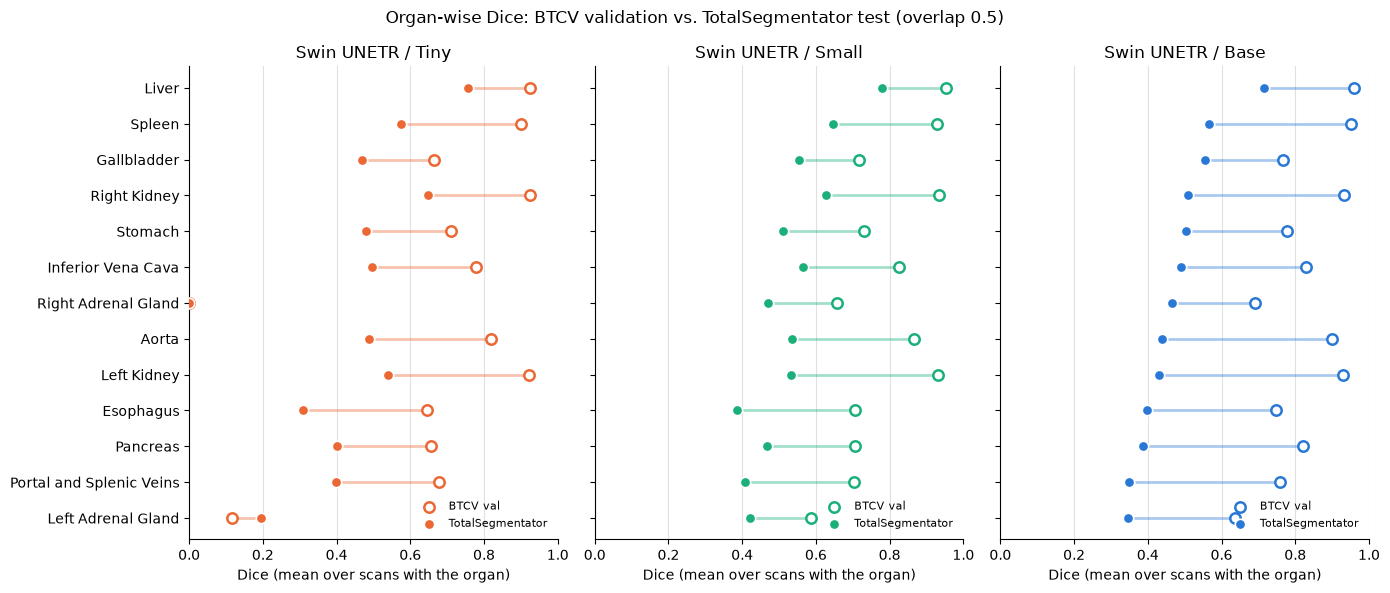

In [6]:
# Dice per organ: BTCV (hollow) -> TotalSegmentator (filled), one panel per model
order = organ_dice["base"].sort_values().index
y = np.arange(len(order))
fig, axes = plt.subplots(1, 3, figsize=(14, 6), sharey=True, sharex=True)
for ax, m in zip(axes, MODELS):
    c = MODEL_COLORS[m]
    ax.hlines(y, btcv_dice.loc[order, m], organ_dice.loc[order, m], color=c, alpha=0.4, linewidth=2, zorder=1)
    ax.scatter(btcv_dice.loc[order, m], y, facecolor="white", edgecolor=c, s=56, linewidth=1.8, zorder=3, label="BTCV val")
    ax.scatter(organ_dice.loc[order, m], y, color=c, s=56, edgecolor="white", linewidth=1.2, zorder=3, label="TotalSegmentator")
    ax.set_title(MODEL_NAMES[m])
    ax.set_xlim(0, 1)
    ax.set_xlabel("Dice (mean over scans with the organ)")
    ax.grid(axis="x", color="#e0e0e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right", fontsize=8)
axes[0].set_yticks(y, order)
fig.suptitle("Organ-wise Dice: BTCV validation vs. TotalSegmentator test (overlap 0.5)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ood_organwise_dice.png", dpi=200, bbox_inches="tight", pad_inches=0.2)
plt.show()

### Robustness per organ under BTCV-like conditions
Raw TotalSegmentator Dice mixes several shifts (cropped organs, children, non-abdominal scans). Here only
**complete organs in adult abdominal scans** are kept, and Dice is expressed as % of the model's BTCV Dice.

In [7]:
adult_abd = set(scans.case[scans.abdominal & (scans.age >= 18)])
cond = present[~present.truncated & present.case.isin(adult_abd)]
ts_cond = cond.pivot_table(index="organ", columns="model", values="dice", aggfunc="mean").loc[ORGANS, MODELS]
retained = (100 * ts_cond / btcv_dice).round(0)
robust = pd.concat({"Dice BTCV": btcv_dice, "Dice TS adult abdominal complete": ts_cond, "Retained [%]": retained}, axis=1)
robust.to_csv(METRICS_DIR / f"ood_organ_robustness_overlap{OVERLAP}.csv")
print(f"{len(adult_abd)} adult abdominal scans, {cond[cond.model == 'base'].shape[0]} complete organ instances; "
      f"mean Dice Base {cond[cond.model == 'base'].dice.mean():.3f}, Small {cond[cond.model == 'small'].dice.mean():.3f}, "
      f"Tiny {cond[cond.model == 'tiny'].dice.mean():.3f}")
robust.sort_values(("Retained [%]", "base"), ascending=False).round(2)

57 adult abdominal scans, 620 complete organ instances; mean Dice Base 0.597, Small 0.664, Tiny 0.555


Dice BTCV              \
model                         tiny small  base   
organ                                            
Liver                         0.92  0.95  0.96   
Right Adrenal Gland           0.00  0.66  0.69   
Gallbladder                   0.66  0.72  0.77   
Inferior Vena Cava            0.78  0.83  0.83   
Stomach                       0.71  0.73  0.78   
Spleen                        0.90  0.93  0.95   
Esophagus                     0.64  0.71  0.75   
Left Adrenal Gland            0.12  0.59  0.64   
Aorta                         0.82  0.87  0.90   
Right Kidney                  0.92  0.93  0.93   
Left Kidney                   0.92  0.93  0.93   
Pancreas                      0.65  0.71  0.82   
Portal and Splenic Veins      0.68  0.70  0.76   

                         Dice TS adult abdominal complete              \
model                                                tiny small  base   
organ                                                                   
Liver                                                0.89  0.91  0.87   
Right Adrenal Gland                                  0.00  0.62  0.61   
Gallbladder                                          0.61  0.64  0.64   
Inferior Vena Cava                                   0.71  0.76  0.69   
Stomach                                              0.63  0.65  0.62   
Spleen                                               0.74  0.79  0.71   
Esophagus                                            0.40  0.55  0.56   
Left Adrenal Gland                                   0.26  0.56  0.47   
Aorta                                                0.61  0.69  0.62   
Right Kidney                                         0.75  0.72  0.59   
Left Kidney                                          0.67  0.65  0.54   
Pancreas                                             0.53  0.61  0.47   
Portal and Splenic Veins                             0.48  0.48  0.41   

                         Retained [%]              
model                            tiny small  base  
organ                                              
Liver                            96.0  96.0  91.0  
Right Adrenal Gland               NaN  95.0  89.0  
Gallbladder                      92.0  89.0  84.0  
Inferior Vena Cava               91.0  93.0  83.0  
Stomach                          88.0  89.0  80.0  
Spleen                           82.0  85.0  75.0  
Esophagus                        62.0  79.0  75.0  
Left Adrenal Gland              226.0  95.0  73.0  
Aorta                            75.0  80.0  69.0  
Right Kidney                     81.0  77.0  63.0  
Left Kidney                      73.0  70.0  58.0  
Pancreas                         81.0  86.0  58.0  
Portal and Splenic Veins         71.0  69.0  54.0

## OOD failure modes
1. **Field of view**: TotalSegmentator scans are cropped differently from BTCV (head, chest, legs, whole body).
   Organs can be cut off at the top/bottom of the scan (*truncated*), or be absent while the model still predicts
   them (*phantom* organs).
2. **Distant fragments**: in long scans, small false-positive islands far from the organ inflate HD95
   (as in Task 3, compare HD95 of the full prediction with HD95 of its largest connected component).

In [8]:
# Truncated vs complete organs (organ present in the scan)
trunc = (present.groupby(["model", "truncated"]).dice.agg(["mean", "median", "size"])
         .rename(index=MODEL_NAMES, level=0).rename(index={True: "truncated", False: "complete"}, level=1))
trunc

mean  median  size
model              truncated                     
Swin UNETR / Base  complete   0.540   0.650   751
                   truncated  0.287   0.101   271
Swin UNETR / Small complete   0.594   0.704   751
                   truncated  0.357   0.273   271
Swin UNETR / Tiny  complete   0.495   0.570   751
                   truncated  0.301   0.122   271

In [9]:
# Phantom organs: predicted although the organ is not in the scan
absent = ood[~ood.organ_in_gt]
ph = absent.groupby("model").agg(
    absent_instances=("phantom", "size"),
    phantom=("phantom", "sum"),
    phantom_over_1ml=("phantom_ml", lambda s: int((s > 1).sum())),
    median_phantom_ml=("phantom_ml", lambda s: s[s > 0].median()),
).loc[MODELS].rename(index=MODEL_NAMES)
ph["phantom rate [%]"] = 100 * ph.phantom / ph.absent_instances
print("Phantom organs (organ absent in ground truth, model predicts >= 1 voxel):")
display(ph)

# Where does it happen? Base model, scans grouped by how many BTCV organs they contain
b = ood[ood.model == "base"].merge(scans[["case", "n_organs"]], on="case")
b["scan group"] = pd.cut(b.n_organs, [-1, 0, 6, 12, 13], labels=["0 organs", "1-6", "7-12", "all 13"])
display(b[~b.organ_in_gt].groupby("scan group", observed=True).agg(
    absent=("phantom", "size"), phantom=("phantom", "sum"), total_phantom_ml=("phantom_ml", "sum")).round(1))

print("Largest phantom predictions (Base):")
display(b[b.phantom].nlargest(8, "phantom_ml")[["case", "organ", "phantom_ml", "n_organs"]]
        .merge(meta[["case", "study_type"]], on="case").round(1))

Phantom organs (organ absent in ground truth, model predicts >= 1 voxel):


,absent_instances,phantom,phantom_over_1ml,median_phantom_ml,phantom rate [%]
model,,,,,
Swin UNETR / Tiny,395,192,81,0.574,48.608
Swin UNETR / Small,395,228,101,0.614,57.722
Swin UNETR / Base,395,183,75,0.564,46.329


,absent,phantom,total_phantom_ml
scan group,,,
0 organs,156,54,6393.8
1-6,185,89,5798.6
7-12,54,40,68.2


Largest phantom predictions (Base):


,case,organ,phantom_ml,n_organs,study_type
0,s1725,Liver,1346.3,0,ct head
1,s1112,Liver,1280.5,2,ct angiography neck
2,s1932,Liver,1161.9,0,ct head
3,s1075,Liver,1114.1,2,ct angiography head
4,s1933,Liver,1055.3,0,ct head
5,s1626,Liver,1031.0,1,NaN
6,s1641,Liver,1012.6,0,ct head
7,s1458,Liver,956.8,2,NaN


In [10]:
# Do distant fragments drive HD95? Full prediction vs largest connected component only
c = cc.merge(ood[["model", "case", "organ", "hd95", "dice"]], on=["model", "case", "organ"])
c["hd95_drop_pct"] = 100 * (c.hd95 - c.hd95_largest_cc) / c.hd95
frag = c.groupby("model").agg(
    pairs=("hd95", "size"),
    hd95_median=("hd95", "median"),
    hd95_largest_cc_median=("hd95_largest_cc", "median"),
    hd95_mean=("hd95", "mean"),
    hd95_largest_cc_mean=("hd95_largest_cc", "mean"),
    share_with_fragments=("components", lambda s: (s > 1).mean() * 100),
    share_hd95_halved=("hd95_drop_pct", lambda s: (s >= 50).mean() * 100),
).loc[MODELS].rename(index=MODEL_NAMES)
frag

,pairs,hd95_median,hd95_largest_cc_median,hd95_mean,hd95_largest_cc_mean,share_with_fragments,share_hd95_halved
model,,,,,,,
Swin UNETR / Tiny,913,90.648,36.404,141.232,70.649,96.605,37.788
Swin UNETR / Small,978,39.915,23.413,136.189,62.115,91.104,30.368
Swin UNETR / Base,943,45.294,26.681,120.146,65.691,86.426,26.723


## Robustness to scan and patient characteristics (Base)
Per scan: mean Dice over **complete (non-truncated)** organs present in the scan, so field-of-view cropping does not
dominate. Groups with fewer than 4 scans are merged into "other". Small groups → read as indications, not proof.

size   mean  median
study type   abdomen                       6  0.513   0.490
             abdomen-pelvis               11  0.615   0.712
             chest-abdomen-pelvis         11  0.616   0.667
             neck-chest-abdomen-pelvis    12  0.533   0.767
             other                        18  0.387   0.411
             polytrauma                    4  0.468   0.490
             unknown                      18  0.275   0.190
age group    65+                          29  0.498   0.544
             adult (18-64)                36  0.531   0.471
             child (<18)                  14  0.172   0.132
manufacturer ge                           17  0.284   0.251
             philips                       6  0.518   0.522
             siemens                      45  0.530   0.649
             unknown                      12  0.417   0.381
pathology    no_pathology                 10  0.459   0.480
             other                         6  0.698   0.704
             trauma                        4  0.497   0.529
             tumor                        15  0.561   0.667
             unclear                      11  0.559   0.544
             unknown                      29  0.315   0.326
             vascular                      5  0.466   0.457
sex          f                            37  0.439   0.419
             m                            42  0.470   0.455
             unknown                       1  0.812   0.812

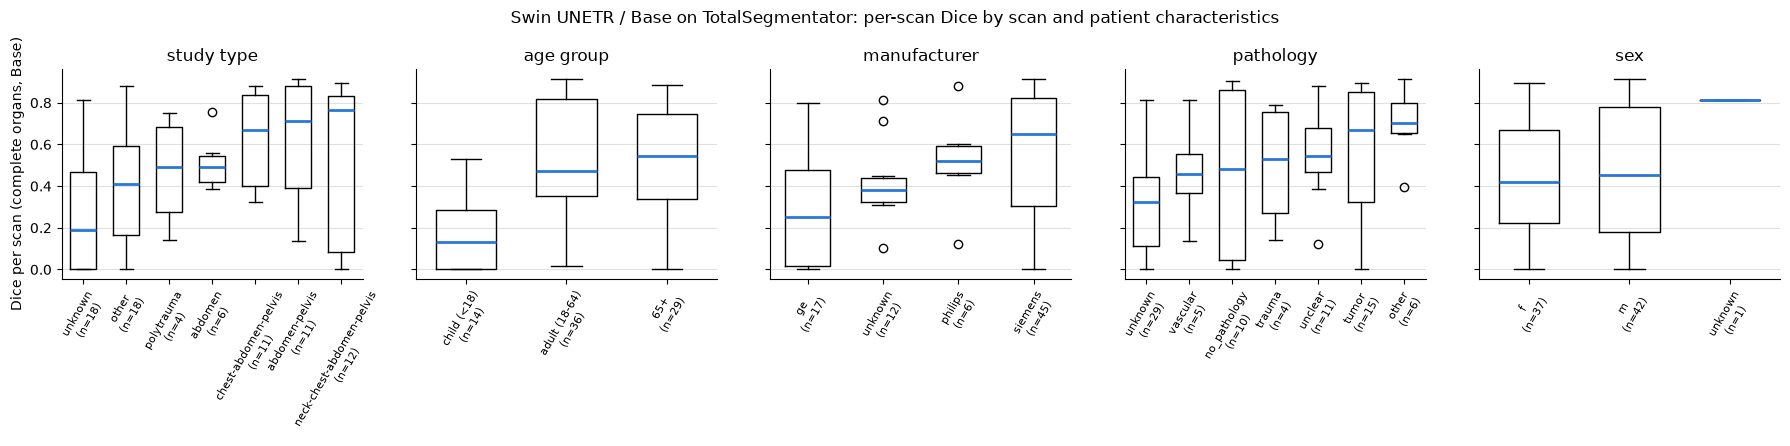

In [11]:
ps = (ood[(ood.model == "base") & ood.organ_in_gt & ~ood.truncated].groupby("case").dice.mean()
      .rename("dice").reset_index().merge(scans, on="case"))

def lump(s, min_n=4):
    s = s.fillna("unknown")
    counts = s.value_counts()
    return s.where(s.map(counts) >= min_n, "other")

ps["study type"] = lump(ps.study_type.str.replace("ct ", "", regex=False))
ps["age group"] = pd.cut(ps.age, [0, 17, 64, 120], labels=["child (<18)", "adult (18-64)", "65+"]).astype(str).replace("nan", "unknown")
ps["manufacturer"] = lump(ps.manufacturer)
ps["pathology"] = lump(ps.pathology)
ps["sex"] = ps.gender.fillna("unknown")

factors = ["study type", "age group", "manufacturer", "pathology", "sex"]
summary = pd.concat({f: ps.groupby(f).dice.agg(["size", "mean", "median"]) for f in factors})
summary.to_csv(METRICS_DIR / "ood_robustness_base.csv")
display(summary.round(3))

fig, axes = plt.subplots(1, len(factors), figsize=(18, 4.5), sharey=True)
for ax, f in zip(axes, factors):
    groups = ps.groupby(f).dice
    labels = [k for k, _ in sorted(groups, key=lambda kv: kv[1].median())]
    ax.boxplot([ps.dice[ps[f] == k] for k in labels], tick_labels=[f"{k}\n(n={(ps[f] == k).sum()})" for k in labels],
               widths=0.6, medianprops=dict(color=MODEL_COLORS["base"], linewidth=2), showfliers=True)
    ax.set_title(f)
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.grid(axis="y", color="#e0e0e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Dice per scan (complete organs, Base)")
fig.suptitle("Swin UNETR / Base on TotalSegmentator: per-scan Dice by scan and patient characteristics")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ood_robustness_base.png", dpi=200, bbox_inches="tight", pad_inches=0.2)
plt.show()

## Contrast phase (Base, adult abdominal scans, complete organs)
TotalSegmentator mixes non-contrast, arterial and venous scans; BTCV is portal-venous. The metadata has no phase,
so the median HU inside the ground-truth aorta is used as a proxy. Also checks where missed kidney/aorta voxels go
(left/right swap vs background).

In [12]:
import nibabel as nib
from src.config import OOD_LABEL_DIR, PREDICTIONS_DIR

adults = [c for c in sorted(abdominal) if meta.set_index("case").loc[c, "age"] >= 18]
idx = {name: k for k, name in BTCV_ORGANS.items()}
conf = {o: np.zeros(14, int) for o in ("Right Kidney", "Left Kidney", "Aorta")}
hu_rows = []
for c in adults:  # ~1 min
    g = np.asarray(nib.load(OOD_LABEL_DIR / f"{c}_label.nii.gz").dataobj)
    p = np.asarray(nib.load(PREDICTIONS_DIR / "ood" / "base" / f"{c}.nii.gz").dataobj)
    ct = np.asarray(nib.load(OOD_DATASET_DIR / c / "ct.nii.gz").dataobj)
    for o in conf:
        conf[o] += np.bincount(p[g == idx[o]], minlength=14)
    hu_rows.append({"case": c, "aorta_hu": np.median(ct[g == idx["Aorta"]])})

names = {0: "background", **BTCV_ORGANS}
print("Where do ground-truth voxels end up? (Base, adult abdominal scans)")
for o, v in conf.items():
    top = sorted(enumerate(v / v.sum() * 100), key=lambda x: -x[1])[:3]
    print(f"  {o:13s} ->", ", ".join(f"{names[i]} {s:.1f}%" for i, s in top))

hu = pd.DataFrame(hu_rows)
hu["phase (aorta HU)"] = pd.cut(hu.aorta_hu, [-1e9, 100, 200, 1e9], labels=["<100 (non-contrast / late)", "100-200 (venous)", ">200 (arterial)"])
b = ood[(ood.model == "base") & ood.organ_in_gt & ~ood.truncated & ood.case.isin(adults)].merge(hu, on="case")
phase = b.pivot_table(index="phase (aorta HU)", columns="organ", values="dice", aggfunc="mean", observed=True)[ORGANS]
phase.insert(0, "n scans", hu.groupby("phase (aorta HU)", observed=True).size())
phase.to_csv(METRICS_DIR / "ood_contrast_phase_base.csv")
phase.round(2)

Where do ground-truth voxels end up? (Base, adult abdominal scans)
  Right Kidney  -> Right Kidney 55.3%, background 38.2%, Left Kidney 3.1%
  Left Kidney   -> Left Kidney 47.7%, background 46.2%, Spleen 2.6%
  Aorta         -> background 57.5%, Aorta 40.7%, Spleen 0.6%


organ,n scans,Spleen,Right Kidney,Left Kidney,Gallbladder,Esophagus,Liver,Stomach,Aorta,Inferior Vena Cava,Portal and Splenic Veins,Pancreas,Right Adrenal Gland,Left Adrenal Gland
phase (aorta HU),,,,,,,,,,,,,,
<100 (non-contrast / late),17,0.59,0.17,0.19,0.55,0.32,0.79,0.49,0.59,0.53,0.08,0.26,0.52,0.28
100-200 (venous),26,0.80,0.80,0.75,0.68,0.70,0.93,0.80,0.76,0.80,0.70,0.68,0.71,0.64
>200 (arterial),14,0.69,0.64,0.49,0.71,0.46,0.84,0.40,0.36,0.62,0.26,0.27,0.54,0.33


## Example: brain segmented as liver (s1112, neck CT angiography incl. head)

predicted liver: 1281 ml, of which 99.0% inside the brain; median HU 51


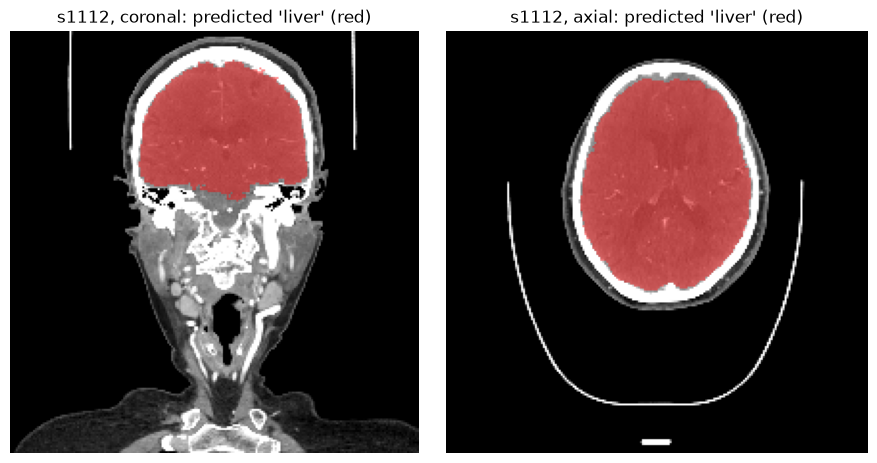

In [13]:
case = "s1112"
ct = np.asarray(nib.load(OOD_DATASET_DIR / case / "ct.nii.gz").dataobj)
p = np.asarray(nib.load(PREDICTIONS_DIR / "ood" / "base" / f"{case}.nii.gz").dataobj)
brain = np.asarray(nib.load(OOD_DATASET_DIR / case / "segmentations" / "brain.nii.gz").dataobj) > 0
liver = p == idx["Liver"]
print(f"predicted liver: {liver.sum() * VOXEL_ML:.0f} ml, of which {100 * (liver & brain).sum() / liver.sum():.1f}% inside the brain; "
      f"median HU {np.median(ct[liver]):.0f}")

y = int(np.argwhere(liver)[:, 1].mean())  # coronal slice through the centre of the predicted 'liver'
z = int(np.argwhere(liver)[:, 2].mean())
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, img, msk, title in ((axes[0], ct[:, y, :].T, liver[:, y, :].T, "coronal"), (axes[1], ct[:, :, z].T, liver[:, :, z].T, "axial")):
    ax.imshow(np.clip(img, -175, 250), cmap="gray", origin="lower")  # the window the model sees
    ax.imshow(np.ma.masked_where(~msk, msk), cmap="autumn", alpha=0.45, origin="lower")
    ax.set_title(f"{case}, {title}: predicted 'liver' (red)")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ood_brain_as_liver.png", dpi=200, bbox_inches="tight", pad_inches=0.1)
plt.show()

## Best and worst example (complete13 scans, official Dice)

In [14]:
per_case = (ood[ood.case.isin(complete13)].groupby(["model", "case"])
            .agg(dice=("dice", "mean"), hd95_median=("hd95", "median"), missed=("missed", "sum"),
                 truncated=("truncated", "sum"))
            .reset_index().merge(meta[["case", "study_type", "age", "manufacturer", "pathology"]], on="case"))
for label, row in (("Best", per_case.loc[per_case.dice.idxmax()]), ("Worst", per_case.loc[per_case.dice.idxmin()])):
    print(f"{label:5s}: {MODEL_NAMES[row.model]} / {row.case}  Dice = {row.dice * 100:.1f}%  HD95 median = "
          f"{row.hd95_median:.1f} mm  missed = {row.missed}  truncated organs = {row.truncated}  "
          f"({row.study_type}, age {row.age}, {row.manufacturer}, {row.pathology})")
per_case[per_case.model == "base"].sort_values("dice").iloc[np.r_[0:5, -5:0]]

Best : Swin UNETR / Base / s0244  Dice = 88.5%  HD95 median = 3.4 mm  missed = 0  truncated organs = 3  (ct abdomen-pelvis, age 87.0, siemens, tumor)
Worst: Swin UNETR / Base / s0753  Dice = 1.2%  HD95 median = 142.2 mm  missed = 6  truncated organs = 12  (ct chest-neck, age 71.0, siemens, no_pathology)


,model,case,dice,hd95_median,missed,truncated,study_type,age,manufacturer,pathology
19,base,s0753,0.012,142.192,6,12,ct chest-neck,71.0,siemens,no_pathology
13,base,s0470,0.050,113.108,3,10,ct chest-abdomen,49.0,philips,unclear
41,base,s1806,0.103,321.837,1,2,ct neck-chest-abdomen-pelvis,35.0,NaN,NaN
37,base,s1564,0.126,31.820,6,3,NaN,2.0,siemens,NaN
23,base,s1152,0.143,312.018,0,0,ct polytrauma,78.0,siemens,trauma
9,base,s0440,0.876,3.674,0,0,ct chest-abdomen-pelvis,57.0,siemens,no_pathology
24,base,s1174,0.878,20.893,0,0,ct chest-abdomen-pelvis,60.0,siemens,no_pathology
5,base,s0236,0.882,4.743,0,1,ct abdomen-pelvis,75.0,siemens,tumor
15,base,s0499,0.882,4.500,0,0,ct chest-abdomen,60.0,philips,unclear
6,base,s0244,0.885,3.354,0,3,ct abdomen-pelvis,87.0,siemens,tumor


## Do Dice and HD95 agree?

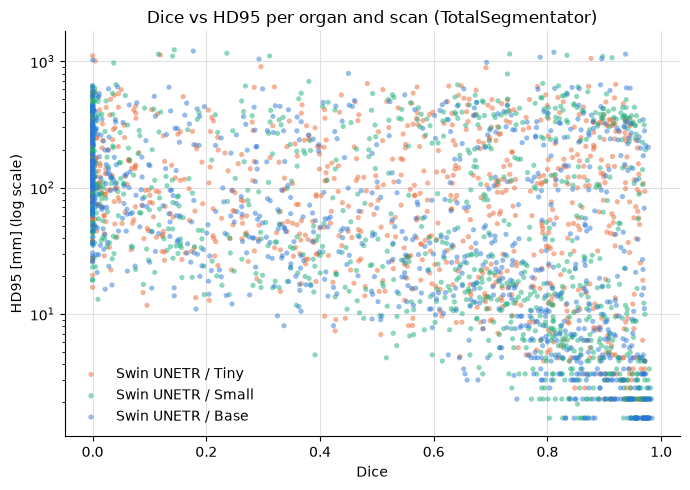

Spearman Dice vs HD95 (TS): -0.43


,Rank by Dice,Rank by HD95 median
Swin UNETR / Tiny,3,3
Swin UNETR / Small,1,1
Swin UNETR / Base,2,2


In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
for m in MODELS:
    d = present[(present.model == m) & present.hd95.notna()]
    ax.scatter(d.dice, d.hd95, color=MODEL_COLORS[m], label=MODEL_NAMES[m], s=14, alpha=0.5, edgecolor="none")
ax.set_yscale("log")
ax.set_xlabel("Dice")
ax.set_ylabel("HD95 [mm] (log scale)")
ax.set_title("Dice vs HD95 per organ and scan (TotalSegmentator)")
ax.grid(color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ood_dice_vs_hd95.png", dpi=200, bbox_inches="tight", pad_inches=0.2)
plt.show()

print("Spearman Dice vs HD95 (TS):", round(present[["dice", "hd95"]].corr(method="spearman").iloc[0, 1], 2))
ts = overall.xs("TS complete13 (53)", level=1)
pd.DataFrame({
    "Rank by Dice": ts["Dice official [%]"].rank(ascending=False).astype(int),
    "Rank by HD95 median": ts["HD95 median [mm]"].rank().astype(int),
})